The following runs inside the BenchMAX environment.

# Train CFR baselines

How close is a learned multi-agent policy to equilibrium? We train **CFR** and **CFR+** at several iteration budgets, then evaluate their exact exploitability. Kuhn poker is small enough to enumerate its game tree, so this experiment separates training behavior from sampling noise in evaluation.

CFR is a game-solving baseline that uses the full game tree. This example needs only the base BenchMAX installation and the notebook dependencies.

The largest run uses 1,000 iterations. In this implementation, each iteration updates one player, alternating between the two. Each plotted point starts training from scratch.

## Setup

In [1]:
from benchmax import load_game

game = load_game("kuhn_poker")
budgets = (1, 5, 10, 25, 50, 100, 250, 500, 1_000)
algorithms = {"cfr": "CFR", "cfr_plus": "CFR+"}
seed = 7

## Train and evaluate

`train` returns a policy profile for all players. For these algorithms, that profile represents the implementation's **averaged strategy**, rather than only the last iteration's strategy. `game.evaluate` computes the configured exact best-response metrics.

The seed is included in the training call, but this deterministic CFR implementation does not use it. Different seeds would therefore repeat the same calculation.

In [2]:
from benchmax.training import train

results = {}
for algorithm in algorithms:
    rows = []
    
    for iterations in budgets:
        policy = train(game, algorithm, iterations=iterations, seed=seed)
        metrics = game.evaluate(policy)
        rows.append({"iterations": iterations, **metrics})
    
    results[algorithm] = rows

print(f"{'Algorithm':<10} {'Iterations':>10} {'Exploitability':>16} {'NashConv':>12}")
for algorithm, rows in results.items():
    final = rows[-1]
    print(f"{algorithms[algorithm]:<10} {final['iterations']:>10} "
          f"{final['exploitability']:>16.6f} {final['nash_conv']:>12.6f}")

Algorithm  Iterations   Exploitability     NashConv
CFR              1000         0.001932     0.003863
CFR+             1000         0.000357     0.000714


## Compare convergence

Lower exploitability means less incentive for either player to deviate unilaterally. In this two-player zero-sum game, exploitability is half of NashConv, which sums the two players' best-response improvements. Zero indicates equilibrium, up to numerical precision.

The logarithmic axes show both early progress and later changes. Iteration count measures the algorithm's work budget; this plot does not compare wall-clock performance.

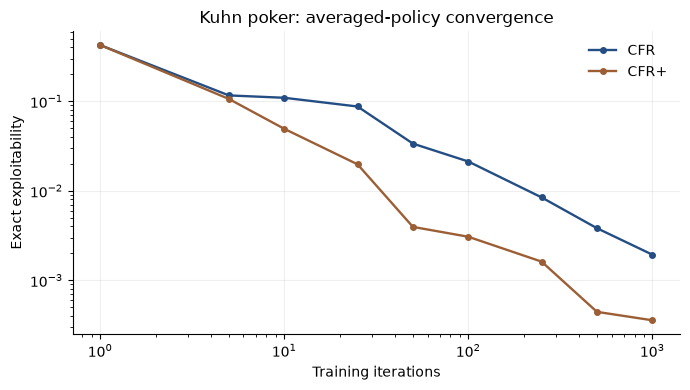

In [3]:
import matplotlib.pyplot as plt
import numpy as np

colors = {"cfr": "#244e83", "cfr_plus": "#9b5e35"}
fig, ax = plt.subplots(figsize=(7, 4))

for algorithm, rows in results.items():
    exploitability = np.array([row["exploitability"] for row in rows])
    ax.loglog(budgets, exploitability, marker="o", linewidth=1.7,
              markersize=4, color=colors[algorithm], label=algorithms[algorithm])

ax.set(xlabel="Training iterations", ylabel="Exact exploitability",
       title="Kuhn poker: averaged-policy convergence")
ax.grid(True, which="major", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## Expected return is a different question

Expected returns describe what happens when the profile's players face each other. Exploitability asks what a best-response opponent could gain by deviating. A profile can have plausible self-play returns and still be exploitable; a negative return for one player is not itself evidence of poor learning in an asymmetric game.

Inspect both quantities rather than using self-play reward as a substitute for equilibrium evaluation:

In [4]:
for algorithm, rows in results.items():
    final = rows[-1]

    print(algorithms[algorithm])
    print("  Expected returns:", final["expected_returns"])
    print("  Best-response improvements:", final["player_improvements"], "\n")

CFR
  Expected returns: {0: -0.05555213704239803, 1: 0.05555213704239803}
  Best-response improvements: {0: 0.0007530825875289027, 1: 0.0031099270990291306} 

CFR+
  Expected returns: {0: -0.05555623236952845, 1: 0.05555623236952845}
  Best-response improvements: {0: 0.0004322093959131801, 1: 0.00028173056218228076} 



Both methods reduce exploitability over the budgets shown. Compare their curves at the same iteration count, but avoid generalizing a ranking from a single small game. The path need not improve monotonically at every iteration, and the returned average can behave differently from the current strategy.

These values are exact tree-based evaluations of the returned profiles, subject to floating-point arithmetic. They are not estimates with sampling confidence intervals. The experiment restarts training for every budget; the points are not saved checkpoints from one resumable run.

Full-tree methods become expensive as games grow. CFR also needs observations that distinguish the information sets used by its tabular policies. These policies currently remain in memory; durable CFR artifacts and detached training jobs are unsupported.